# Day 1 lecture: Exploring data

<p class="lead">
Periods 4 to 6 of Day 1, and the bridge to Lab 1. A routine for meeting a new dataset: structure and quality checks, missing values and what to do about them, distributions and skew, pivot tables and grouped summaries, correlation and its limits, confounding and Simpson's paradox, and charts that still work with tens of thousands of points.
</p>

Run each code cell with **Shift + Enter**, in order. The examples use the **mpg** car data, a real university admissions table and synthetic data. Lab 1 uses the diamonds data; this lecture deliberately does **not**, so that you practise each skill here and apply it yourself in the lab.

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder; everything loads from `data/`.
- **Route A (Try JupyterLab):** upload this notebook and `data/mpg.csv`, run `%pip install seaborn` in a first cell, and change `"data/mpg.csv"` to `"mpg.csv"` in Part 2.

---

## What you will be able to do

1. Run a fixed **exploration routine** on any new table and report what you find.
2. Find missing, duplicated and impossible values, and explain why the reason for missingness matters.
3. Describe a distribution by its **centre, spread and shape**, and say when the median is the better summary.
4. Build and read **pivot tables**, always with the counts behind each cell.
5. Read a **correlation matrix** and explain five ways a correlation can mislead.
6. Recognise **confounding** and **Simpson's paradox**, and make a fairer comparison.
7. Choose a chart that still works when points overlap (**over-plotting**).

| Part | Topic | Period |
|---|---|---|
| 1 | The exploration routine | P4 |
| 2 | Structure, data quality and missing values | P4 |
| 3 | Distributions and skew | P4–P5 |
| 4 | Pivot tables and grouped summaries | P5 |
| 5 | Correlation and its limits | P5 |
| 6 | Confounding and Simpson's paradox | P6 |
| 7 | Over-plotting and its fixes | P6 |
| 8 | Lab 1 briefing | P6 |
| 9 | Business case, practice, quiz and summary | Self-study |

> **Reading**
>
> Read Chapter 1 of the course reading packet, Section 1.5 especially, for what `describe()`, `isnull().sum()`, `groupby()` and `corr()` each reveal and the two easy mistakes with `corr()`. This lecture adds distributions, missingness, Simpson's paradox and over-plotting.

---

## Part 1: The exploration routine

This morning ended with a rule: **summarise and plot**. This afternoon turns it into a routine you can run on any table, in this order. Each step answers a question the next step depends on.

| Step | Question | Code |
|---|---|---|
| 1 | What is one row? (the **grain**) | Read the source; `head()` |
| 2 | How big is it? | `shape` |
| 3 | What type is each column? | `info()`, `dtypes` |
| 4 | What is missing? | `isnull().sum()` |
| 5 | Anything duplicated or impossible? | `duplicated().sum()`, `describe()` min and max |
| 6 | What do the categories look like? | `value_counts()` |
| 7 | How is each number distributed? | `describe()`, histogram, box or violin plot |
| 8 | How do groups compare? | `groupby`, `pivot_table`, with counts |
| 9 | How do numbers move together? | `corr()`, heatmap, scatter or hexbin |
| 10 | What else could explain it? | Split by a third variable |

Steps 1–6 are about **trust**: can these numbers be used at all? Steps 7–10 are about **patterns**. Skipping the first half is how good charts of bad data get made.

---

## Part 2: Structure, data quality and missing values

The **mpg** data describes 398 car models sold in the 1970s and early 1980s: fuel economy in miles per US gallon, engine size, power, weight in pounds, acceleration, model year and region of origin. One row is **one car model in one model year**. (Day 5's Lab 5 builds a regression on it; today we only explore.)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cars = pd.read_csv("data/mpg.csv")     # Route A: "mpg.csv"
print("Rows, columns:", cars.shape)
cars.head()

Rows, columns: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [2]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


`info()` gives three things at once: the column **types**, the **non-null count** per column, and the memory used. Compare each non-null count with the number of rows: any column with fewer has missing values.

> **Predict, then run**
>
> From the `info()` output alone, which column has missing values, and how many? Write your answer, then check it with the next cell.

In [3]:
print("Missing values per column:")
print(cars.isnull().sum())
print("\nFully duplicated rows:", cars.duplicated().sum())

Missing values per column:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Fully duplicated rows: 0


In [4]:
cars[cars["horsepower"].isnull()][["name", "model_year", "cylinders", "weight", "horsepower"]]

,name,model_year,cylinders,weight,horsepower
32,ford pinto,71,4,2046,NaN
126,ford maverick,74,6,2875,NaN
330,renault lecar deluxe,80,4,1835,NaN
336,ford mustang cobra,80,4,2905,NaN
354,renault 18i,81,4,2320,NaN
374,amc concord dl,82,4,3035,NaN


Looking at the missing rows themselves, not just the count, is a habit worth keeping: here they are ordinary cars from several years, which suggests the values were simply not recorded, not that some kind of car is missing.

### Validity: ranges and codes

In [5]:
cars.describe().round(1)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.0,398.0,398.0,392.0,398.0,398.0,398.0
mean,23.5,5.5,193.4,104.5,2970.4,15.6,76.0
std,7.8,1.7,104.3,38.5,846.8,2.8,3.7
min,9.0,3.0,68.0,46.0,1613.0,8.0,70.0
25%,17.5,4.0,104.2,75.0,2223.8,13.8,73.0
50%,23.0,4.0,148.5,93.5,2803.5,15.5,76.0
75%,29.0,8.0,262.0,126.0,3608.0,17.2,79.0
max,46.6,8.0,455.0,230.0,5140.0,24.8,82.0


In [6]:
print(cars["origin"].value_counts())
print()
print(cars["cylinders"].value_counts().sort_index())

origin
usa       249
japan      79
europe     70
Name: count, dtype: int64

cylinders
3      4
4    204
5      3
6     84
8    103
Name: count, dtype: int64


> **Check your understanding**
>
> 1. `model_year` runs from 70 to 82. What does a value of 76 mean, and why is this a **validity** and **consistency** risk if this table were joined to one that stores years as 1976?
> 2. Only a handful of cars have 3 or 5 cylinders. What does that mean for any average calculated for those groups?

### Why the reason for missingness matters

What you may do with a missing value depends on **why** it is missing.

| Kind | Meaning | Business example | Is dropping the rows safe? |
|---|---|---|---|
| Missing completely at random | Missingness has nothing to do with any value | A till lost records on random days because of a power cut | Usually: you lose rows, not truth |
| Missing at random (given other columns) | Missingness depends on something you **have** recorded | Older stores do not record loyalty IDs; store age is in the data | Only if you compare within groups of that column |
| Missing not at random | Missingness depends on the **missing value itself** | High earners skip the income question; unhappy customers skip the survey | No: the remaining rows are biased |

The next cell simulates the third kind: a salary survey of 2,000 employees where the higher someone's salary, the more likely they leave the question blank. Salaries are in neutral currency units per month.

In [7]:
rng = np.random.default_rng(1012)
true_salary = rng.lognormal(np.log(9000), 0.4, 2000).round(-1)
skip_chance = np.clip((true_salary - 6000) / 20000, 0.02, 0.9)    # richer people skip more often
answered = rng.random(2000) > skip_chance

survey = pd.DataFrame({"salary": np.where(answered, true_salary, np.nan)})
print(f"Answered: {answered.sum()} of 2000")
print(f"True mean salary (known only in a simulation): {true_salary.mean():,.0f}")
print(f"Mean of the answers that were given:           {survey['salary'].mean():,.0f}")

filled = survey["salary"].fillna(survey["salary"].mean())
print(f"\nStandard deviation of the answers:              {survey['salary'].std():,.0f}")
print(f"Standard deviation after filling with the mean: {filled.std():,.0f}")

Answered: 1622 of 2000
True mean salary (known only in a simulation): 9,718
Mean of the answers that were given:           8,820

Standard deviation of the answers:              3,170
Standard deviation after filling with the mean: 2,854


Two lessons:

- When missingness depends on the value, the observed mean is **biased**, and no amount of data fixes it. Only a better collection method does (for example, salary bands instead of an exact figure).
- Filling gaps with the mean (**mean imputation**) keeps the row count but **shrinks the spread**, because hundreds of identical values are added in the middle. It also keeps the bias. Use it only when few values are missing, and say that you did.

> **Misconception: "no missing values means the data is complete"**
>
> A column can have no `NaN` and still be incomplete: a missing measurement is sometimes stored as 0, −1, 999 or an empty string. Always read the min and max in `describe()` and ask whether each extreme value is physically possible.

---

## Part 3: Distributions and skew

A **distribution** is how the values of one column are spread out. Describe it with three words:

| Aspect | Measures | Question |
|---|---|---|
| **Centre** | Mean, median, mode | What is a typical value? |
| **Spread** | Standard deviation, interquartile range (IQR), range | How different are the values from each other? |
| **Shape** | Skewness, number of peaks, tails, gaps | Is it symmetric? Is it really one group? |

**Right skew** (positive skew) means a long tail of large values: most values are modest, a few are very large. Money is almost always right-skewed: incomes, house prices, order values, claims. In a right-skewed distribution the mean is pulled toward the tail, so **mean > median**.

The next cell generates 5,000 online orders for an imaginary home-goods shop, in currency units.

In [8]:
rng = np.random.default_rng(2026)
shop = pd.DataFrame({"order_value": rng.lognormal(np.log(60), 0.75, 5000).round(2)})
value = shop["order_value"]

print(f"Mean:     {value.mean():8.2f}")
print(f"Median:   {value.median():8.2f}")
print(f"Skewness: {value.skew():8.2f}   (0 = symmetric; above 1 = strongly right-skewed)")
print(f"Share of orders below the mean: {(value < value.mean()).mean() * 100:.0f}%")

Mean:        79.05
Median:      60.80
Skewness:     3.09   (0 = symmetric; above 1 = strongly right-skewed)
Share of orders below the mean: 64%


> **Predict, then run**
>
> The mean is called the "average order". What share of customers actually spent **less** than it? Check the last line above. Would you report the mean or the median to a manager asking "what does a typical customer spend?"

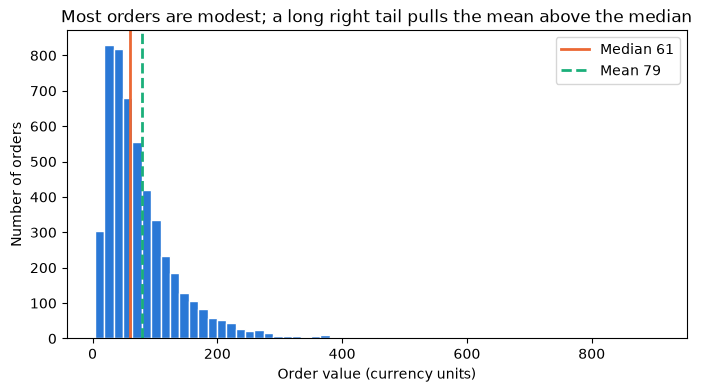

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(value, bins=60, color="#2a78d6", edgecolor="white")
ax.axvline(value.median(), color="#eb6834", linewidth=2, label=f"Median {value.median():.0f}")
ax.axvline(value.mean(), color="#1baf7a", linewidth=2, linestyle="--", label=f"Mean {value.mean():.0f}")
ax.set_title("Most orders are modest; a long right tail pulls the mean above the median")
ax.set_xlabel("Order value (currency units)")
ax.set_ylabel("Number of orders")
ax.legend()
plt.show()

### The number of bins changes the story

> **Predict, then run**
>
> The next cell draws the same data with 6 bins and with 150 bins. Which one will look smoother? Which one could hide a second peak?

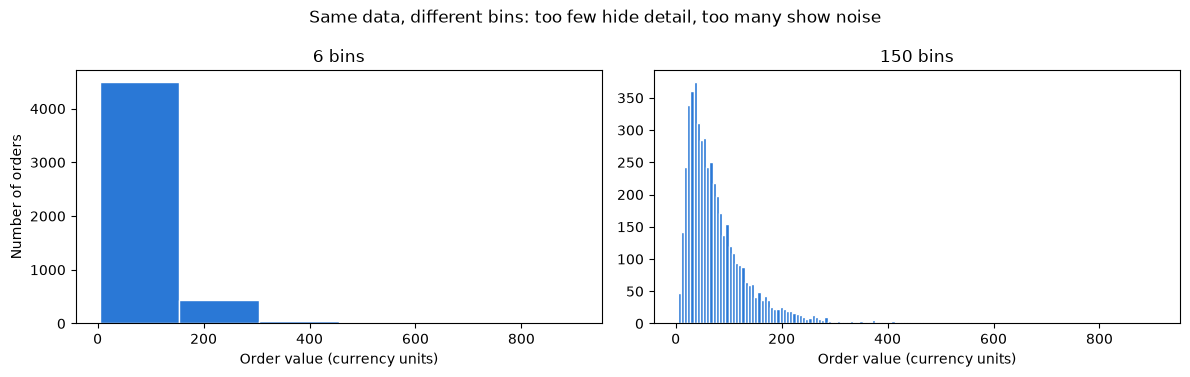

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=False)
for ax, bins in zip(axes, [6, 150]):
    ax.hist(value, bins=bins, color="#2a78d6", edgecolor="white")
    ax.set_title(f"{bins} bins")
    ax.set_xlabel("Order value (currency units)")
axes[0].set_ylabel("Number of orders")
fig.suptitle("Same data, different bins: too few hide detail, too many show noise")
plt.tight_layout()
plt.show()

### Two remedies for skew: a log scale, and the box plot

On a **log scale** each step is a multiplication (10, 100, 1,000), so a right-skewed variable often looks symmetric. A **box plot** shows the median (line), the middle half of the data (the box, from the 25th to the 75th percentile: the IQR), whiskers to the furthest points within 1.5 IQR, and dots beyond that.

IQR: 64.13  | upper fence: 195.80  | orders beyond it: 278


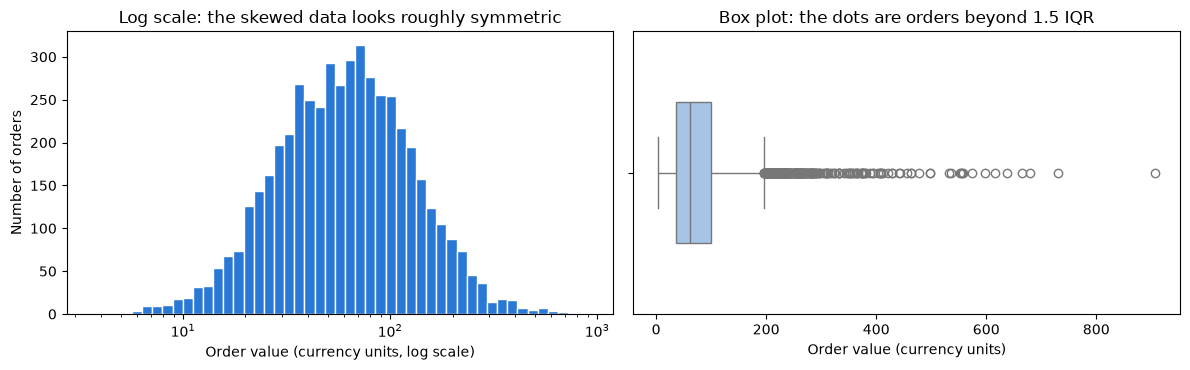

In [11]:
q1, q3 = value.quantile([0.25, 0.75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
print(f"IQR: {iqr:.2f}  | upper fence: {upper_fence:.2f}  | orders beyond it: {(value > upper_fence).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(value, bins=np.logspace(np.log10(value.min()), np.log10(value.max()), 50),
             color="#2a78d6", edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_title("Log scale: the skewed data looks roughly symmetric")
axes[0].set_xlabel("Order value (currency units, log scale)")
axes[0].set_ylabel("Number of orders")
sns.boxplot(x=value, color="#9cc3ef", width=0.5, ax=axes[1])      # a horizontal box plot
axes[1].set_title("Box plot: the dots are orders beyond 1.5 IQR")
axes[1].set_xlabel("Order value (currency units)")
plt.tight_layout()
plt.show()

> **Misconception: "the dots on a box plot are errors to delete"**
>
> In skewed data, points beyond the whisker are expected: here they are the shop's biggest customers. A value is an **error** only if it is impossible (a negative price, a weight of 0). A value that is merely **unusual** is information.

### More than one peak usually means more than one group

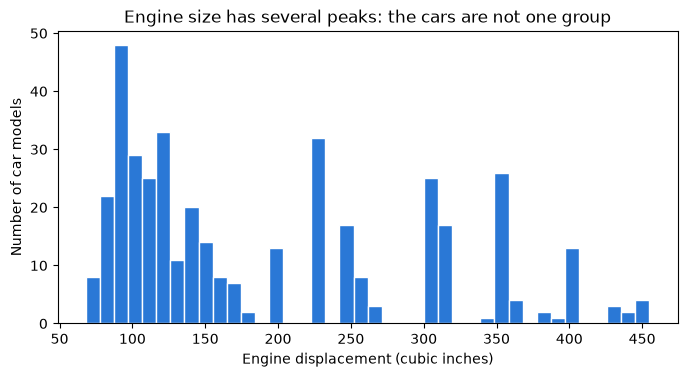

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(cars["displacement"], bins=40, color="#2a78d6", edgecolor="white")
ax.set_title("Engine size has several peaks: the cars are not one group")
ax.set_xlabel("Engine displacement (cubic inches)")
ax.set_ylabel("Number of car models")
plt.show()

> **Predict, then run**
>
> Which column in `cars` do you think explains the separate peaks? Make a guess, then run the next cell, which draws one violin per number of cylinders.

A **violin plot** is a box plot's richer cousin: its width at each height shows how many values sit there, so it shows several peaks and long tails that a box hides.

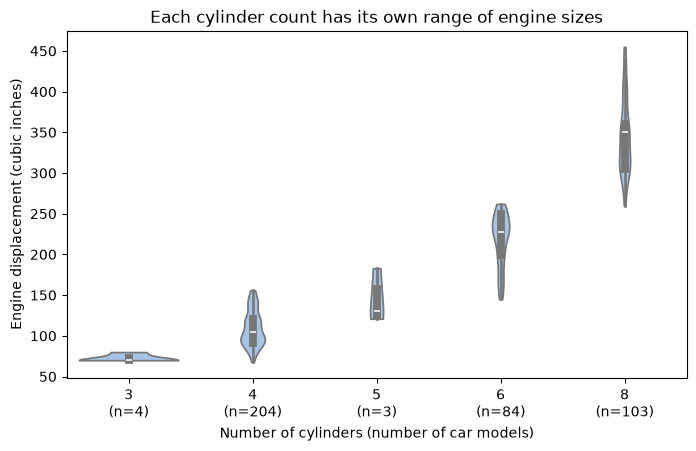

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.violinplot(data=cars, x="cylinders", y="displacement", color="#9cc3ef", cut=0, ax=ax)
counts = cars["cylinders"].value_counts().sort_index()
ax.set_xticks(range(len(counts)))
ax.set_xticklabels([f"{c}\n(n={n})" for c, n in counts.items()])
ax.set_title("Each cylinder count has its own range of engine sizes")
ax.set_xlabel("Number of cylinders (number of car models)")
ax.set_ylabel("Engine displacement (cubic inches)")
plt.show()

Writing the count under each violin matters: a violin drawn from four cars looks as confident as one drawn from two hundred.

> **Software note: violins and colour**
>
> Here every violin has one colour (`color=`). To give each category its own colour, newer seaborn (0.13 and later) uses `hue=` set to the same column plus `legend=False`. Older versions ignore `legend=False` and draw thin, shifted violins. The Lab 1 guide's pitfalls table explains the fix.

---

## Part 4: Pivot tables and grouped summaries

A **pivot table** puts one category down the side, another across the top, and a summary of a number in each cell. It is the workhorse of descriptive and diagnostic analytics, in Python, Excel and Tableau alike.

> **Predict, then run**
>
> Before running: will European, Japanese or US cars have the highest average mpg? And among **4-cylinder** cars only?

In [14]:
mpg_pivot = pd.pivot_table(cars, index="origin", columns="cylinders", values="mpg", aggfunc="mean")
count_pivot = pd.pivot_table(cars, index="origin", columns="cylinders", values="mpg", aggfunc="count")

print("Average mpg by origin and cylinders (NaN = no such cars)")
print(mpg_pivot.round(1))
print("\nNumber of car models behind each average")
print(count_pivot.fillna(0).astype(int))

Average mpg by origin and cylinders (NaN = no such cars)
cylinders     3     4     5     6     8
origin                                 
europe      NaN  28.4  27.4  20.1   NaN
japan      20.6  31.6   NaN  23.9   NaN
usa         NaN  27.8   NaN  19.7  15.0

Number of car models behind each average
cylinders  3   4  5   6    8
origin                      
europe     0  63  3   4    0
japan      4  69  0   6    0
usa        0  72  0  74  103


Read the **count** table first. Several cells are empty (`NaN`) because the combination does not exist in this data: no US car here has 3 or 5 cylinders, and only US cars have 8. Other cells rest on three or four cars and should not be compared with cells resting on a hundred.

### Margins, and the average-of-averages trap

`margins=True` adds an "All" row and column. Those margins are calculated from the **rows**, so they are weighted by how many cars each group has. Averaging the cell averages instead gives a different, usually wrong, number.

In [15]:
with_margins = pd.pivot_table(cars, index="origin", values="mpg", aggfunc=["mean", "count"], margins=True)
print(with_margins.round(2))

region_means = cars.groupby("origin")["mpg"].mean()
print(f"\nMean of all cars:                      {cars['mpg'].mean():.2f}")
print(f"Average of the three region averages:  {region_means.mean():.2f}")

         mean count
          mpg   mpg
origin             
europe  27.89    70
japan   30.45    79
usa     20.08   249
All     23.51   398

Mean of all cars:                      23.51
Average of the three region averages:  26.14


> **Check your understanding**
>
> Why is the average of the three region averages higher than the mean of all cars? (Hint: look at the counts.) Which number answers "what was the average fuel economy of a car model on sale"?

### The same summary with `groupby`, and shares with `crosstab`

`groupby().agg()` gives the same numbers as a one-way pivot, with several summaries side by side. `crosstab(..., normalize="index")` turns counts into **shares of each row**, which is how you compare groups of different sizes.

In [16]:
cars.groupby("origin").agg(
    car_models=("mpg", "size"),
    mean_mpg=("mpg", "mean"),
    median_mpg=("mpg", "median"),
    mean_weight_lb=("weight", "mean"),
).round(1)

,car_models,mean_mpg,median_mpg,mean_weight_lb
origin,,,,
europe,70,27.9,26.5,2423.3
japan,79,30.5,31.6,2221.2
usa,249,20.1,18.5,3361.9


In [17]:
(pd.crosstab(cars["origin"], cars["cylinders"], normalize="index") * 100).round(1)

cylinders,3,4,5,6,8
origin,,,,,
europe,0.0,90.0,4.3,5.7,0.0
japan,5.1,87.3,0.0,7.6,0.0
usa,0.0,28.9,0.0,29.7,41.4


> **Predict, then run**
>
> In the share table, about what share of US car models had 8 cylinders, and of Japanese models? Keep this in mind for Part 6: if 8-cylinder cars use more fuel, how could that alone affect the region comparison?

### Ordering categories

Pivot tables sort text categories **alphabetically**, which is rarely the order a reader expects ("Average", "Good", "Poor" instead of Poor → Average → Good). Fix it with `reindex` on the result, or by making the column an ordered category before you pivot.

In [18]:
cars["era"] = pd.cut(cars["model_year"], bins=[69, 73, 77, 82], labels=["1970-73", "1974-77", "1978-82"])
era_order = ["1978-82", "1974-77", "1970-73"]          # newest first, chosen on purpose
pd.pivot_table(cars, index="era", columns="origin", values="mpg", aggfunc="mean",
               observed=True).reindex(era_order).round(1)

origin,europe,japan,usa
era,,,
1978-82,32.5,33.5,25.3
1974-77,25.8,28.1,19.0
1970-73,24.7,24.7,16.0


---

## Part 5: Correlation and its limits

The **Pearson correlation coefficient** *r* measures how closely two numbers follow a **straight line** together. It runs from −1 (perfect downward line) through 0 (no straight-line pattern) to +1 (perfect upward line). Intuitively, it averages, over all rows, "how far above or below its mean is x, times how far above or below its mean is y", after putting both on the same scale.

| \|r\| | Usual reading |
|---|---|
| below 0.3 | weak |
| 0.3 to 0.7 | moderate |
| above 0.7 | strong |

These cut-offs are conventions, not laws: in some fields an *r* of 0.3 is valuable.

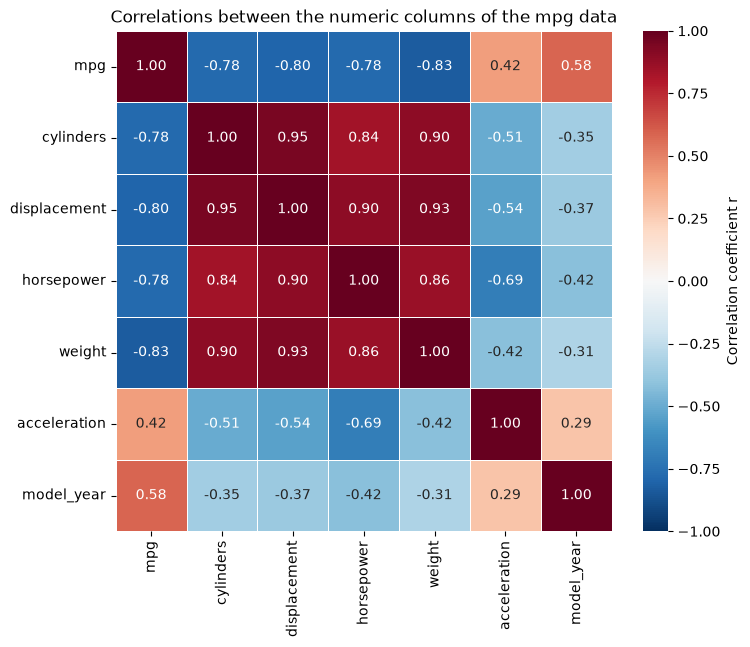

In [19]:
numeric = cars.select_dtypes(include="number")
corr_matrix = numeric.corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, linewidths=0.5,
            cbar_kws={"label": "Correlation coefficient r"}, ax=ax)
ax.set_title("Correlations between the numeric columns of the mpg data")
plt.show()

How to read a correlation heatmap:

- The diagonal is always 1: each column with itself. The matrix is symmetric, so read only one triangle.
- Fix the colour scale at −1 to +1 (`vmin`, `vmax`), with a diverging palette centred on 0, so that colours mean the same thing on every chart.
- Look for **blocks**: here cylinders, displacement, horsepower and weight are all strongly related to each other. They largely measure one thing, "how big the car is". Day 4 calls this **multicollinearity**.
- `origin` and `name` are not in the matrix: they are text. A categorical column can matter a great deal and still never appear in `corr()`. Use `groupby` for it.

> **Check your understanding**
>
> Which pair of different columns has the strongest correlation in this matrix? Is it positive or negative, and what does that mean in words?

### Five ways a correlation misleads

The next cell builds four small synthetic datasets, each designed to break the naive reading of *r*.

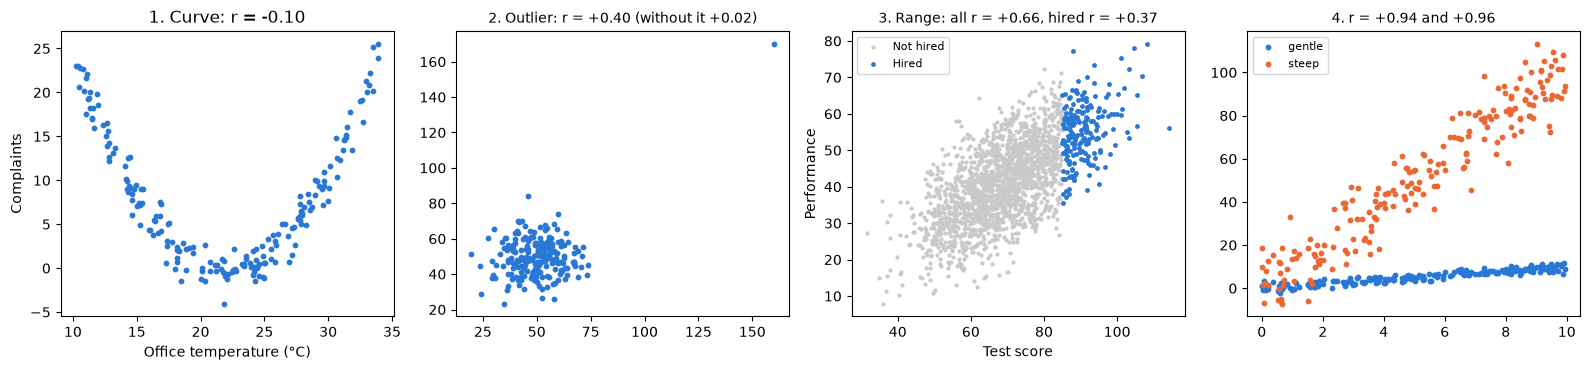

In [20]:
rng = np.random.default_rng(55)
n = 200

# 1. A strong curved relationship: temperature and comfort complaints
temp = rng.uniform(10, 34, n)
complaints = (temp - 22) ** 2 / 6 + rng.normal(0, 1.5, n)

# 2. No relationship, plus one extreme point
x_noise = rng.normal(50, 10, n)
y_noise = rng.normal(50, 10, n)
x_out = np.append(x_noise, 160)
y_out = np.append(y_noise, 170)

# 3. Restricted range: a test score and job performance, but only high scorers were hired
score = rng.normal(70, 12, 2000)
performance = 0.6 * score + rng.normal(0, 8, 2000)
hired = score > 85

# 4. The same r, different slopes
x_s = rng.uniform(0, 10, n)
y_gentle = 1 * x_s + rng.normal(0, 1, n)
y_steep = 10 * x_s + rng.normal(0, 10, n)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
axes[0].scatter(temp, complaints, s=10, color="#2a78d6")
axes[0].set_title(f"1. Curve: r = {np.corrcoef(temp, complaints)[0, 1]:+.2f}")
axes[0].set_xlabel("Office temperature (°C)"); axes[0].set_ylabel("Complaints")
axes[1].scatter(x_out, y_out, s=10, color="#2a78d6")
axes[1].set_title(f"2. Outlier: r = {np.corrcoef(x_out, y_out)[0, 1]:+.2f} "
                  f"(without it {np.corrcoef(x_noise, y_noise)[0, 1]:+.2f})", fontsize=10)
axes[2].scatter(score, performance, s=4, color="#c9c9c9", label="Not hired")
axes[2].scatter(score[hired], performance[hired], s=6, color="#2a78d6", label="Hired")
axes[2].set_title(f"3. Range: all r = {np.corrcoef(score, performance)[0, 1]:+.2f}, "
                  f"hired r = {np.corrcoef(score[hired], performance[hired])[0, 1]:+.2f}", fontsize=10)
axes[2].set_xlabel("Test score"); axes[2].set_ylabel("Performance"); axes[2].legend(fontsize=8)
axes[3].scatter(x_s, y_gentle, s=10, color="#2a78d6", label="gentle")
axes[3].scatter(x_s, y_steep, s=10, color="#eb6834", label="steep")
axes[3].set_title(f"4. r = {np.corrcoef(x_s, y_gentle)[0, 1]:+.2f} and {np.corrcoef(x_s, y_steep)[0, 1]:+.2f}",
                  fontsize=10)
axes[3].legend(fontsize=8)
plt.tight_layout()
plt.show()

| Panel | Trap | Lesson |
|---|---|---|
| 1 | A strong pattern, *r* near 0 | *r* measures **straight-line** patterns only; plot first |
| 2 | One point creates a correlation | Check outliers; Spearman's rank correlation (below) is less sensitive |
| 3 | The correlation shrinks inside a selected group | Looking only at hired staff, customers who stayed, or products that survived understates the relationship |
| 4 | Same *r*, ten times the slope | *r* says how **tight** the line is, not how **much** y changes per unit of x; that is the slope (Day 4) |

The fifth trap needs time: **two things that both grow over time correlate**, whatever they are.

In [21]:
years = np.arange(2010, 2026)
rng = np.random.default_rng(7)
phones_sold = 100 + 9 * (years - 2010) + rng.normal(0, 4, len(years))        # invented series
cinema_tickets = 50 + 3 * (years - 2010) + rng.normal(0, 3, len(years))      # invented series

print(f"r between the two yearly totals:           {np.corrcoef(phones_sold, cinema_tickets)[0, 1]:+.2f}")
print(f"r between their year-on-year changes:      {np.corrcoef(np.diff(phones_sold), np.diff(cinema_tickets))[0, 1]:+.2f}")

rank_r = pd.Series(x_out).corr(pd.Series(y_out), method="spearman")
print(f"\nPanel 2 again, Spearman rank correlation:  {rank_r:+.2f}")

r between the two yearly totals:           +0.98
r between their year-on-year changes:      -0.20

Panel 2 again, Spearman rank correlation:  +0.02


Two series that both trend upward correlate strongly even when they have nothing to do with each other. Comparing the **changes** removes the shared trend, and the correlation largely disappears. Day 3's forecasting lecture returns to this.

> **Misconception: "correlation means causation" (and its opposite)**
>
> A correlation is a description of how two columns moved together in this data. It can arise from a cause, a reverse cause, a third factor, selection, a shared trend or chance. The opposite mistake is just as common: "*r* is near 0, so there is no relationship" (panel 1).

---

## Part 6: Confounding and Simpson's paradox

A **confounder** is a third variable that affects both the thing you compare **by** and the thing you **measure**, so that the comparison mixes two effects. Written as arrows: Z → X and Z → Y. Comparing Y across X then shows partly the effect of Z.

In Part 4, US cars had lower average mpg and far more 8-cylinder engines. Is "US-made" the reason for lower fuel economy, or is engine size? Engine size is a candidate confounder: it differs between regions **and** it affects fuel use.

### Simpson's paradox: a real case

The most famous example comes from graduate admissions at the University of California, Berkeley, in 1973. The table below is the widely published version for the six largest departments (Bickel, Hammel & O'Connell, 1975).

In [22]:
admissions = pd.DataFrame({
    "department": list("AABBCCDDEEFF"),
    "gender": ["Men", "Women"] * 6,
    "applicants": [825, 108, 560, 25, 325, 593, 417, 375, 191, 393, 373, 341],
    "admitted":   [512, 89, 353, 17, 120, 202, 138, 131, 53, 94, 22, 24],
})

overall = admissions.groupby("gender")[["applicants", "admitted"]].sum()
overall["admitted (%)"] = (100 * overall["admitted"] / overall["applicants"]).round(1)
print("All six departments together")
print(overall)

All six departments together
        applicants  admitted  admitted (%)
gender                                    
Men           2691      1198          44.5
Women         1835       557          30.4


> **Predict, then run**
>
> Overall, men were admitted at a clearly higher rate. Predict: in how many of the six departments will men have the higher admission rate?

In [23]:
admissions["admitted (%)"] = (100 * admissions["admitted"] / admissions["applicants"]).round(1)
by_dept = admissions.pivot_table(index="department", columns="gender", values=["admitted (%)", "applicants"])
by_dept

admitted (%)       applicants       
gender              Men Women        Men  Women
department                                     
A                  62.1  82.4      825.0  108.0
B                  63.0  68.0      560.0   25.0
C                  36.9  34.1      325.0  593.0
D                  33.1  34.9      417.0  375.0
E                  27.7  23.9      191.0  393.0
F                   5.9   7.0      373.0  341.0

In most departments women were admitted at a rate similar to or **higher** than men, yet overall they were admitted less often. Look at the applicant counts: most women applied to departments C–F, which admitted few applicants of either gender; most men applied to A and B, which admitted most applicants. The **department** is the lurking variable: gender affected which department people applied to, and department affected the chance of admission.

**Simpson's paradox** is the name for a trend that appears in every group, or most groups, and reverses (or disappears) when the groups are combined. It happens when the groups differ in size **and** in their baseline rate.

### A business version, and a fairer comparison

Two support teams resolve customer tickets. Team North handles many **hard** tickets (technical faults); Team South mostly **easy** ones (password resets). Synthetic numbers:

In [24]:
tickets = pd.DataFrame({
    "team": ["North", "North", "South", "South"],
    "ticket_type": ["Easy", "Hard", "Easy", "Hard"],
    "tickets": [300, 700, 900, 100],
    "resolved_first_time": [282, 420, 801, 52],
})
tickets["rate (%)"] = (100 * tickets["resolved_first_time"] / tickets["tickets"]).round(1)
print(tickets.pivot_table(index="team", columns="ticket_type", values="rate (%)"))

team_total = tickets.groupby("team")[["tickets", "resolved_first_time"]].sum()
team_total["rate (%)"] = (100 * team_total["resolved_first_time"] / team_total["tickets"]).round(1)
print()
print(team_total)

ticket_type  Easy  Hard
team                   
North        94.0  60.0
South        89.0  52.0

       tickets  resolved_first_time  rate (%)
team                                         
North     1000                  702      70.2
South     1000                  853      85.3


North is better at **both** kinds of ticket and worse overall, because it carries most of the hard work. A manager who ranked teams on the overall rate would reward the wrong team.

The fix is to compare like with like. **Standardisation** applies one common ticket mix to both teams' rates, so the mix no longer differs:

In [25]:
common_mix = tickets.groupby("ticket_type")["tickets"].sum() / tickets["tickets"].sum()
print("Common mix:", (common_mix * 100).round(1).to_dict(), "(% of all tickets)")

rates = tickets.pivot_table(index="team", columns="ticket_type", values="rate (%)")
standardised = (rates * common_mix).sum(axis=1).round(1)
print("\nFirst-time resolution (%) if both teams had the same ticket mix:")
print(standardised)

Common mix: {'Easy': 60.0, 'Hard': 40.0} (% of all tickets)

First-time resolution (%) if both teams had the same ticket mix:
team
North    80.4
South    74.2
dtype: float64


### How to look for confounding

1. Ask: **what else differs** between the groups I am comparing? (Size, mix, location, time, who chose to be in them.)
2. **Split** by that variable (pivot with it as a second dimension) and compare within each level.
3. **Show the counts**, so you see where each group's weight lies.
4. If the groups differ in mix, **standardise** or compare like with like.
5. Remember that you can only split by confounders you have **recorded**. The strongest protection is a designed comparison, such as a randomised trial.

> **Misconception: "with enough data, the confounding goes away"**
>
> Berkeley had over 4,500 applicants. More rows make each rate more precise, but they make a confounded comparison precisely wrong. Only splitting, standardising or a better design helps.

---

## Part 7: Over-plotting and its fixes

With a few hundred points a scatter plot is honest. With tens of thousands, points pile on top of each other and the densest region looks no darker than a sparse one: **over-plotting**. The next cell generates 80,000 synthetic taxi trips, distance against fare, including a flat-fare airport route.

In [26]:
rng = np.random.default_rng(80)
n_city = 76000
distance = rng.gamma(1.8, 3.0, n_city)
fare = 12 + 2.4 * distance + rng.normal(0, 3, n_city)
airport_distance = rng.normal(28, 2.5, 4000)
airport_fare = rng.normal(95, 2, 4000)                       # a flat fare, whatever the distance
trips = pd.DataFrame({"distance_km": np.concatenate([distance, airport_distance]),
                      "fare": np.concatenate([fare, airport_fare])})
trips = trips[(trips["distance_km"] > 0) & (trips["fare"] > 0)]
print("Trips:", len(trips))

Trips: 80000


> **Predict, then run**
>
> 4,000 trips (5%) are airport trips at a flat fare of about 95; the other 76,000 are city trips. In a plain scatter plot, will the airport group look small or large compared with the city trips? In which of the four panels can you see that the city trips are about nineteen times as many, and where most of them lie?

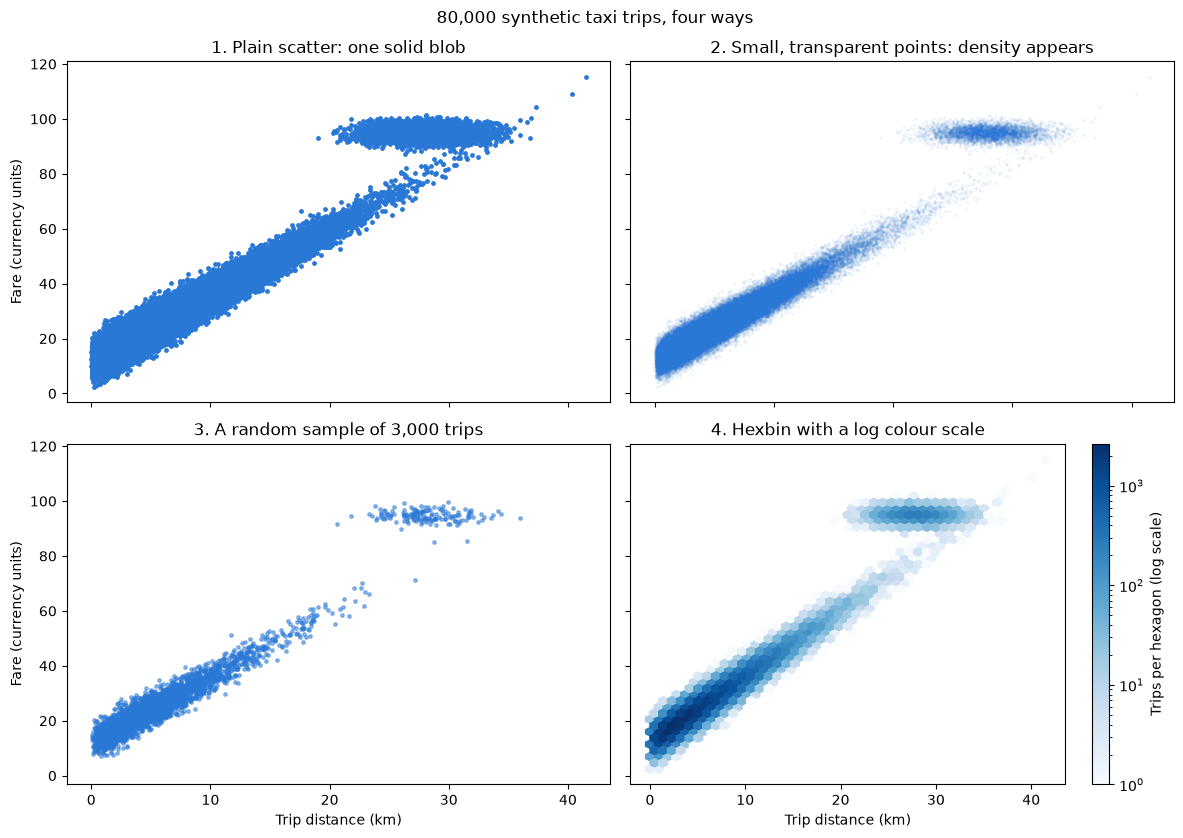

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharex=True, sharey=True)

axes[0, 0].scatter(trips["distance_km"], trips["fare"], s=6, color="#2a78d6")
axes[0, 0].set_title("1. Plain scatter: one solid blob")

axes[0, 1].scatter(trips["distance_km"], trips["fare"], s=2, alpha=0.05, color="#2a78d6")
axes[0, 1].set_title("2. Small, transparent points: density appears")

sample = trips.sample(3000, random_state=1)
axes[1, 0].scatter(sample["distance_km"], sample["fare"], s=6, alpha=0.5, color="#2a78d6")
axes[1, 0].set_title("3. A random sample of 3,000 trips")

hb = axes[1, 1].hexbin(trips["distance_km"], trips["fare"], gridsize=45, cmap="Blues", mincnt=1, bins="log")
fig.colorbar(hb, ax=axes[1, 1], label="Trips per hexagon (log scale)")
axes[1, 1].set_title("4. Hexbin with a log colour scale")

for ax in axes[1]:
    ax.set_xlabel("Trip distance (km)")
for ax in axes[:, 0]:
    ax.set_ylabel("Fare (currency units)")
fig.suptitle("80,000 synthetic taxi trips, four ways")
plt.tight_layout()
plt.show()

| Fix | When to use it | Watch out for |
|---|---|---|
| Smaller points, transparency (`s`, `alpha`) | Up to about 100,000 points | Very rare points can vanish |
| Random sample | Very large data, quick look | Rare groups may be missed; set `random_state` so it repeats |
| **Hexbin** or 2-D histogram | Any size; shows where points concentrate | Choose `gridsize`; a log colour scale stops the densest cell dominating |
| Density contours (`sns.kdeplot`) | Smooth overview of a few groups | Can invent smoothness where data is sparse |
| Jitter (small random shift) | When one axis is a count or category | Never use jittered values for calculations |
| Split into panels or colour by group | When a third variable separates the cloud | Too many colours become unreadable |

A **hexbin** divides the plane into hexagons and colours each by how many points fall inside it. `mincnt=1` leaves empty hexagons blank. Reading it: the darkest region is where most rows lie, and its position on both axes describes the "typical" combination.

### Jitter for discrete values

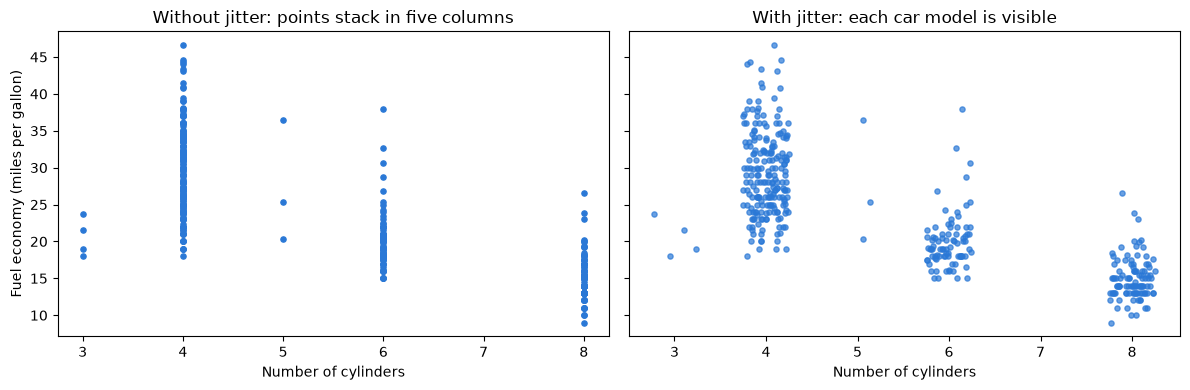

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].scatter(cars["cylinders"], cars["mpg"], s=14, color="#2a78d6")
axes[0].set_title("Without jitter: points stack in five columns")
jitter = np.random.default_rng(3).uniform(-0.25, 0.25, len(cars))   # a small random shift, seeded
axes[1].scatter(cars["cylinders"] + jitter, cars["mpg"], s=14, alpha=0.7, color="#2a78d6")
axes[1].set_title("With jitter: each car model is visible")
for ax in axes:
    ax.set_xlabel("Number of cylinders")
axes[0].set_ylabel("Fuel economy (miles per gallon)")
plt.tight_layout()
plt.show()

---

## Part 8: Lab 1 briefing

Lab 1 applies this afternoon to a dataset of diamonds, for an imaginary jewellery retailer that wants to understand what drives prices. You will:

| Lab part | What you do | Practised today in |
|---|---|---|
| Set-up | Open a notebook and name it as GAP asks | Morning lecture, Part 1 |
| Structure | Inspect types, size, missing values and summary statistics | Part 2 |
| Pivot table | Average price by two categories | Part 4 |
| Visuals | A correlation heatmap, a violin plot and a hexbin plot | Parts 3, 5 and 7 |
| Questions | Short written answers about data quality, an unexpected pivot result and its likely confounder, the strongest correlation, skew and density | Parts 2–7 |
| Export | Restart and run all, PDF, submit on GAP | Morning lecture, Part 1 |

The [Lab 1 guide](guides/lab1_data_exploration.md) has both routes (Try JupyterLab, or the offline bundle), checks you can make, and the known pitfalls. Read the pitfalls before you start.

> **How to answer the questions well**
>
> Name the table or chart you used; quote the number with its unit; say what it **means** (insight, not just statistic); and, for the "why" question, name the third variable and say how you would check it with a pivot table or a chart. Everything you need is in today's lectures; the answers come from **your own output**.

---

## Part 9: Business case, practice, quiz and summary

### Business case for discussion: the hospital league table

A health authority publishes a league table of hospitals ranked by the share of patients who die within 30 days of surgery. Hospital R, a large regional centre, ranks near the bottom; several small local hospitals rank near the top. A newspaper calls Hospital R "the most dangerous in the region".

Discuss in groups (15 minutes):

1. Large regional centres often receive the most complex cases, referred from smaller hospitals. Draw the confounding arrows (Z → X, Z → Y). What is Z?
2. What table would you ask for before agreeing with the newspaper? Name its rows, columns and the counts you would want to see.
3. A small hospital performed 40 operations and had no deaths. How confident can anyone be that its true rate is 0%? Which part of today's lecture warned about this?
4. Some hospitals transfer their sickest patients elsewhere before day 30. Which data quality dimension, and which framing element (Part 4 of the morning lecture), does that affect?
5. Propose a fairer league table, in one paragraph.

### Practice

#### Core

**Core 1.** Run the cell below. Which origin has the heaviest cars on average? Add a line for the **median** weight. Are mean and median close for each region? What does that say about skew?

In [29]:
cars.groupby("origin").agg(car_models=("weight", "size"), mean_weight_lb=("weight", "mean")).round(0)

,car_models,mean_weight_lb
origin,,
europe,70,2423.0
japan,79,2221.0
usa,249,3362.0


**Core 2.** Draw a histogram of `mpg` with 30 bins, a title and labelled axes (with units). Describe its centre, spread and shape in three sentences, and say whether you would report the mean or the median.

**Core 3.** In the `survey` data from Part 2, how many values are missing? Explain to a manager, in two sentences and without the word "MNAR", why the average of the answers is too low.

#### Stretch

**Stretch 1.** Is the region gap in mpg confounded by weight? Create weight bands with `pd.cut(cars["weight"], bins=[0, 2500, 3000, 3500, 6000])` and build a pivot table of mean mpg by origin (rows) and weight band (columns), **with a count table**. Does the US gap shrink within bands? Where are the empty or tiny cells, and what do they mean?

**Stretch 2.** In the taxi data, redraw the hexbin **without** `bins="log"`. What happens to the airport cluster? When would you choose each version?

**Stretch 3.** In the ticket example, change Team North's hard-ticket count to 400 (and its resolved count to 240). Does the paradox remain? Explain using the mix.

#### Challenge

**Challenge 1.** Using the penguins data (`data/penguins.csv`), compute the correlation between `flipper_length_mm` and `bill_depth_mm` for all penguins, then within each species. Explain the difference using the word **confounder**, and draw the chart that shows it.

**Challenge 2.** Write a function `explore(df)` that prints the routine's steps 2–6 for any DataFrame: shape, types, missing values per column, duplicated rows, and the `value_counts()` of every text column. Test it on `cars` and on `signups`-style messy data you make yourself.

### Quiz

1. List the first six steps of the exploration routine. Why do they come before any chart?
2. A column has no missing values but its minimum is −999. What might that mean, and what do you check?
3. In a right-skewed distribution, which is larger, the mean or the median? Name two business variables that are usually right-skewed.
4. What does the "All" margin of a pivot table weight by, and why does an average of group averages differ from it?
5. *r* = 0.05 between temperature and complaints. Can you conclude there is no relationship? Why or why not?
6. Define Simpson's paradox in one sentence. In the Berkeley example, what is the lurking variable, and on what path does it sit?
7. Name three fixes for over-plotting and one risk of each.
8. On a hexbin plot, what does the darkest hexagon tell you?

### Quick reference

| You want to… | Code |
|---|---|
| Size, types and non-null counts | `df.shape`, `df.info()` |
| Missing values per column | `df.isnull().sum()` |
| Duplicated rows | `df.duplicated().sum()` |
| Summary of numeric columns | `df.describe()` |
| Counts of each category | `df["col"].value_counts()` |
| Skewness | `df["col"].skew()` |
| Pivot table, with counts | `pd.pivot_table(df, index=..., columns=..., values=..., aggfunc="mean")`, then `aggfunc="count"` |
| Several summaries per group | `df.groupby("g").agg(name=("col", "mean"), ...)` |
| Shares within each row | `pd.crosstab(df["a"], df["b"], normalize="index")` |
| Correlation matrix and heatmap | `df.select_dtypes(include="number").corr()`, `sns.heatmap(..., vmin=-1, vmax=1)` |
| Rank correlation | `df["x"].corr(df["y"], method="spearman")` |
| Violin plot | `sns.violinplot(data=df, x="group", y="value", cut=0)` |
| Hexbin | `plt.hexbin(x, y, gridsize=40, mincnt=1)` |

### Summary

| Idea | Remember |
|---|---|
| Routine | Trust first (grain, size, types, missing, duplicates, codes), then patterns |
| Missing values | Ask **why** they are missing; dropping or filling can bias results |
| Distributions | Centre, spread, shape; for skewed money data, report the median too |
| Pivot tables | Always show the counts; beware averages of averages; set the category order |
| Correlation | Straight lines only; sensitive to outliers, selection and trends; not a slope, not a cause |
| Confounding | Ask what else differs; split, show counts, standardise |
| Over-plotting | Transparency, sampling, hexbin, jitter, panels |

**Reference:** Bickel, P. J., Hammel, E. A., & O'Connell, J. W. (1975). Sex bias in graduate admissions: Data from Berkeley. *Science*, 187(4175), 398–404.

**Next:** [Lab 1 guide](guides/lab1_data_exploration.md). Earlier today: [Foundations of data-driven decisions](D1_lecture_foundations_decisions.md).

---

## For the facilitator

This notebook fills periods P4–P6 of Day 1, before Lab 1 in P7–P8. No answers are given here.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| P4 | 10 | Part 1: the exploration routine | Put the ten steps on the board; they stay up during the lab |
| P4 | 25 | Part 2: structure, quality, missingness, the salary survey | Ask for the `info()` prediction before running; stress looking at the missing rows themselves |
| P4 | 10 | Part 3: centre, spread, shape; the order-value histogram | Ask "what share spent less than the average?" before revealing it |
| P5 | 10 | Part 3 continued: bins, log scale, box plot, violins | Contrast "unusual" with "impossible" values |
| P5 | 20 | Part 4: pivot tables, counts, margins, crosstab, order | Make students read the count table before the averages |
| P5 | 15 | Part 5: heatmap and the five traps | Hide the panel titles and ask students to guess each *r* first |
| P6 | 20 | Part 6: Berkeley and the support teams | Take the prediction vote; for Berkeley draw gender → department → admission (department is a lurking variable on the path, not a confounder); for the support teams draw the Z → X, Z → Y arrows, with ticket type as Z |
| P6 | 15 | Part 7: over-plotting | Ask how large the airport group looks in each panel, and where most trips lie |
| P6 | 10 | Part 8: Lab 1 briefing | Walk through the guide's pitfalls; check every student has a working route before P7 |

The hospital case, practice and quiz are for the evening or for faster groups. Do not work through the diamonds data or Lab 1's questions in these periods.